# Gráficas del Capítulo 6 — comparación de los tres casos

| Metadato | Valor |
|---|---|
| Tesis | *Transportes Anillares y su importancia en la CDMX y ZMVM* — Maestría en Urbanismo, UNAM FES Acatlán |
| Capítulo | 6 · Comparación Caso 1 (red actual) · Caso 2 (Anillo MB) · Caso 3 (Anillo Metro) |
| Corrida VFTModel | **2026-10-04** (Caso 1 `baseline` :8000 · Caso 2 `scenario_mb` :8001 · Caso 3 `scenario_metro` :8002) |
| Salida | `analysis/notebooks/output/cap6/` — PDF vectorial + PNG 300 dpi |

**Reglas del notebook**
- Solo **lee** archivos existentes: CSV de `tableau/exports/data/garibelt/` y `tableau/connectors/VFTModel/exports/` de este repo, y la distribución de tiempos t_ij del repo hermano `../VFTModel/notebooks/ASSETS/t_distribucion/` (generada por `08_Distribucion_T.ipynb` el 2026-10-23). No modifica datos ni exports.
- Antes de graficar verifica las cifras de control; si alguna no coincide, la celda de control **detiene la ejecución** y no se genera ninguna gráfica.
- Sin títulos dentro de la imagen (los pone el `\caption` de LaTeX). Figuras de 16 cm de ancho, fuente sans de 9–11 pt, fondo blanco.

La celda siguiente imprime la fecha de ejecución y las rutas de entrada con su fecha de modificación.

In [1]:
from datetime import datetime
from pathlib import Path
import ast

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

CORRIDA = "2026-10-04"
FECHA_EJECUCION = datetime.now().strftime("%Y-%m-%d %H:%M")

import os

def es_raiz(p):
    return (p / "CLAUDE.md").exists() and (p / "tableau/exports/data/garibelt").is_dir()

def buscar_raiz():
    """Raíz de Transport-gis-zmvm-mjg sin depender del directorio en que arrancó el kernel.
    Orden: variable TRANSPORT_GIS_ROOT → archivo del notebook (VS Code) → carpetas hacia
    arriba del directorio actual → repo hermano (p. ej. kernel lanzado desde ../VFTModel)."""
    candidatos = []
    if os.environ.get("TRANSPORT_GIS_ROOT"):
        candidatos.append(Path(os.environ["TRANSPORT_GIS_ROOT"]).expanduser())
    nb = globals().get("__vsc_ipynb_file__")
    if nb:
        candidatos += list(Path(nb).resolve().parents)
    for p in [Path.cwd(), *Path.cwd().parents]:
        candidatos += [p, p / "Transport-gis-zmvm-mjg"]
    for p in candidatos:
        if es_raiz(p):
            return p.resolve()
    raise FileNotFoundError(
        "No encontré la raíz de Transport-gis-zmvm-mjg desde " + str(Path.cwd()) +
        ". Define TRANSPORT_GIS_ROOT o ejecuta os.chdir('<ruta>/Transport-gis-zmvm-mjg') antes de esta celda.")

ROOT = buscar_raiz()
# Distribución de t_ij: repo hermano VFTModel (o VFTMODEL_ROOT si está en otra ruta)
VFTMODEL = Path(os.environ.get("VFTMODEL_ROOT", ROOT.parent / "VFTModel")).expanduser()
TDIST = VFTMODEL / "notebooks/ASSETS/t_distribucion"
GAR = ROOT / "tableau/exports/data/garibelt"
VFT = ROOT / "tableau/connectors/VFTModel/exports"
OUT = ROOT / "analysis/notebooks/output/cap6"

ENTRADAS = {
    "fc_base":      GAR / "escenario-base/fc_distribucion_baseline.csv",
    "fc_mb":        GAR / "escenario-mb/fc_distribucion_scenario_mb.csv",
    "fc_metro":     GAR / "escenario-metro/fc_distribucion_scenario_metro.csv",
    "perfil_base":  GAR / "escenario-base/garibelt_perfil_baseline.csv",
    "perfil_mb":    GAR / "escenario-mb/garibelt_perfil_scenario_mb.csv",
    "perfil_metro": GAR / "escenario-metro/garibelt_perfil_scenario_metro.csv",
    "bv":           GAR / "comparativo/bv_comparativo.csv",
    "transicion":   GAR / "comparativo/transicion_bandas.csv",
    "distribucion": GAR / "comparativo/distribucion_bandas.csv",
    "kpi":          GAR / "comparativo/kpi_comparativo.csv",
    "t_base":       VFT / "wdc_t_escalar.csv",
    "t_mb":         VFT / "scenario_mb/wdc_t_escalar.csv",
    "t_metro":      VFT / "scenario_metro/wdc_t_escalar.csv",
    "hist_base":    TDIST / "t_histograma_baseline.csv",
    "hist_mb":      TDIST / "t_histograma_mb.csv",
    "hist_metro":   TDIST / "t_histograma_metro.csv",
    "tres_base":    TDIST / "t_resumen_baseline.csv",
    "tres_mb":      TDIST / "t_resumen_mb.csv",
    "tres_metro":   TDIST / "t_resumen_metro.csv",
    "t_comun":      TDIST / "t_comparativo_comun.csv",
    "t_origen":     TDIST / "t_comparativo_origen.csv",
}
faltan = [str(p) for p in ENTRADAS.values() if not p.exists()]
assert not faltan, f"Faltan archivos de entrada: {faltan}"

print(f"Corrida VFTModel : {CORRIDA}")
print(f"Ejecución        : {FECHA_EJECUCION}")
print(f"Raíz del repo    : {ROOT}")
print(f"VFTModel (t_ij)  : {TDIST}")
print(f"Directorio kernel: {Path.cwd()}")
print(f"Python / librerías: {__import__('sys').version.split()[0]} · pandas {pd.__version__} · matplotlib {mpl.__version__}")
pd.DataFrame(
    [(k, str(p.relative_to(ROOT) if p.is_relative_to(ROOT) else Path("../VFTModel") / p.relative_to(VFTMODEL)), datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M"))
     for k, p in ENTRADAS.items()],
    columns=["clave", "ruta", "modificado"],
)

Corrida VFTModel : 2026-10-04
Ejecución        : 2026-10-24 21:01
Raíz del repo    : /Users/hcabrera/Documents/Personal_Documents/Transport-gis-zmvm-mjg
VFTModel (t_ij)  : /Users/hcabrera/Documents/Personal_Documents/VFTModel/notebooks/ASSETS/t_distribucion
Directorio kernel: /Users/hcabrera/Documents/Personal_Documents/VFTModel
Python / librerías: 3.12.10 · pandas 3.0.3 · matplotlib 3.11.1


,clave,ruta,modificado
0,fc_base,tableau/exports/data/garibelt/escenario-base/f...,2026-10-05 20:53
1,fc_mb,tableau/exports/data/garibelt/escenario-mb/fc_...,2026-10-05 20:53
2,fc_metro,tableau/exports/data/garibelt/escenario-metro/...,2026-10-05 20:53
3,perfil_base,tableau/exports/data/garibelt/escenario-base/g...,2026-10-05 20:53
4,perfil_mb,tableau/exports/data/garibelt/escenario-mb/gar...,2026-10-05 20:53
5,perfil_metro,tableau/exports/data/garibelt/escenario-metro/...,2026-10-05 20:53
6,bv,tableau/exports/data/garibelt/comparativo/bv_c...,2026-10-08 22:55
7,transicion,tableau/exports/data/garibelt/comparativo/tran...,2026-10-08 22:55
8,distribucion,tableau/exports/data/garibelt/comparativo/dist...,2026-10-08 22:55
9,kpi,tableau/exports/data/garibelt/comparativo/kpi_...,2026-10-08 22:55


## Estilo común

Paleta definida **una sola vez**. Cada caso conserva su color en todas las gráficas:
- Caso 1 (red actual): gris neutro — es la referencia.
- Caso 2 (Anillo MB): **ColorAcento** RGB(244, 180, 0).
- Caso 3 (Anillo Metro): **ColorPrincipal** RGB(0, 56, 147).

El amarillo tiene poco contraste sobre blanco (1.8:1), así que las gráficas lo acompañan con etiquetas directas, leyenda y, en las líneas, un trazo distinto por caso.

In [2]:
COLOR_PRINCIPAL = "#003893"   # RGB(0, 56, 147)
COLOR_ACENTO    = "#F4B400"   # RGB(244, 180, 0)
TINTA, TINTA_SEC, REJILLA, FONDO_SUR = "#222222", "#5F5F5F", "#E3E3E3", "#F1F1F1"

CASOS = {   # clave interna → (etiqueta visible, color, estilo de línea)
    "base":  ("Caso 1 (red actual)",   "#7A7A7A",       "-"),
    "mb":    ("Caso 2 (Anillo MB)",    COLOR_ACENTO,    "--"),
    "metro": ("Caso 3 (Anillo Metro)", COLOR_PRINCIPAL, "-."),
}
ETQ = {k: v[0] for k, v in CASOS.items()}
COL = {k: v[1] for k, v in CASOS.items()}
LS  = {k: v[2] for k, v in CASOS.items()}

# Intervalos del valor normalizado (sin nombres cualitativos)
INTERVALO = {"critico": "0–0.25", "debil": "0.25–0.50", "aceptable": "0.50–0.75", "idoneo": "0.75–1.0"}

ANCHO_CM = 16
cm = 1 / 2.54

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans", "Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "legend.frameon": False,
    "axes.edgecolor": TINTA_SEC, "axes.labelcolor": TINTA, "xtick.color": TINTA_SEC,
    "ytick.color": TINTA, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": REJILLA, "grid.linewidth": 0.6,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,          # texto embebido y editable
    "axes.unicode_minus": False,
})

OUT.mkdir(parents=True, exist_ok=True)

def figura(alto_cm):
    return plt.figure(figsize=(ANCHO_CM * cm, alto_cm * cm), layout="constrained")

def guardar(fig, nombre):
    """Guarda PDF vectorial y PNG 300 dpi con nombre fijo, a 16 cm exactos de ancho."""
    meta_pdf = {"Title": nombre, "Subject": f"Tesis Cap. 6 · corrida VFTModel {CORRIDA}", "Creator": "graficas_cap6.ipynb"}
    fig.savefig(OUT / f"{nombre}.pdf", metadata=meta_pdf)
    fig.savefig(OUT / f"{nombre}.png", dpi=300)
    print("→", (OUT / f"{nombre}.pdf").relative_to(ROOT), "y .png")

def tono(hex_color, f):
    """Mezcla un color con blanco (f = 0 → color, f = 1 → blanco), sin transparencia."""
    r, g, b = mpl.colors.to_rgb(hex_color)
    return (r + (1 - r) * f, g + (1 - g) * f, b + (1 - b) * f)

def etiquetar_barras(ax, barras, fmt="{:.0f}", dx=0.3):
    for b in barras:
        w = b.get_width()
        ax.text(w + dx, b.get_y() + b.get_height() / 2, fmt.format(w),
                va="center", ha="left", fontsize=8.5, color=TINTA)

## Carga de datos y tablas derivadas

Todas las cifras de las gráficas salen de estas tablas. Ninguna se escribe a mano.

In [3]:
fc = {k: pd.read_csv(ENTRADAS[f"fc_{k}"]) for k in CASOS}
perfil = {k: pd.read_csv(ENTRADAS[f"perfil_{k}"]) for k in CASOS}
bv = pd.read_csv(ENTRADAS["bv"])
transicion = pd.read_csv(ENTRADAS["transicion"])
t_escalar = {k: pd.read_csv(ENTRADAS[f"t_{k}"]).iloc[0] for k in CASOS}

def sistemas(s):
    """'['MB']' → ['MB']; el campo viene como lista serializada."""
    return ast.literal_eval(s) if isinstance(s, str) else []

# ── G1: estaciones del anillo = ids en Caso 2 y Caso 3 que no existen en Caso 1, sin las 5 paradas CC
ids_base = set(fc["base"].id)
nuevos_mb, nuevos_metro = set(fc["mb"].id) - ids_base, set(fc["metro"].id) - ids_base
nuevos = fc["mb"][fc["mb"].id.isin(nuevos_mb)].copy()
nuevos["es_cc"] = nuevos.sistemas.map(lambda s: "CC" in sistemas(s))
paradas_cc = nuevos[nuevos.es_cc]
anillo = (nuevos[~nuevos.es_cc][["id", "nombre", "fc_total"]].rename(columns={"fc_total": "mb"})
          .merge(fc["metro"][["id", "fc_total"]].rename(columns={"fc_total": "metro"}), on="id", how="left"))
UMBRAL_G1 = 13
g1 = (anillo[(anillo.mb >= UMBRAL_G1) | (anillo.metro >= UMBRAL_G1)]
      .sort_values(["mb", "metro"], ascending=False).reset_index(drop=True))
mediana_fc = float(perfil["base"].set_index("dimension").loc["conectividad_capilar", "valor_bruto"])

# Nodos con FC distinta entre Caso 2 y Caso 3 (nota técnica de la Fase 2 de VFTModel)
fc_23 = fc["mb"][["id", "nombre", "sistemas", "fc_total"]].merge(
    fc["metro"][["id", "fc_total"]], on="id", suffixes=("_mb", "_metro"))
difieren_23 = fc_23[fc_23.fc_total_mb != fc_23.fc_total_metro]

# ── G2: nodos existentes (en Caso 1) cuya FC sube en cada caso, por sistema
exist = fc["base"][["id", "sistemas", "fc_total"]].rename(columns={"fc_total": "base"})
for k in ("mb", "metro"):
    exist = exist.merge(fc[k][["id", "fc_total"]].rename(columns={"fc_total": k}), on="id", how="left")
exist["sistema"] = exist.sistemas.map(sistemas)
ganan = {k: exist[exist[k] > exist.base].explode("sistema") for k in ("mb", "metro")}
pierden = {k: int((exist[k] < exist.base).sum()) for k in ("mb", "metro")}
g2 = pd.DataFrame({k: ganan[k].sistema.value_counts() for k in ("mb", "metro")}).fillna(0).astype(int)
g2 = g2.sort_values(["mb", "metro"], ascending=True)
NOMBRE_SISTEMA = {"CC": "Corredores Concesionados", "RTP": "RTP", "MB": "Metrobús",
                  "METRO": "Metro", "TROLE": "Trolebús", "CBB": "Cablebús", "TL": "Tren Ligero"}

# ── G3: tiempo de viaje promedio T
g3 = pd.Series({k: float(t_escalar[k].T_minutos) for k in CASOS})
T_REFERENCIA = float(t_escalar["base"].referencia_cdmx)   # 85 min, tiempo de referencia del modelo
T_COTA = 180.0                                             # cota de normalización: T_norm = (180 − T) / 95

# ── G4: distribución de t_ij por caso (histograma de 5 min)
hist = {k: pd.read_csv(ENTRADAS[f"hist_{k}"]) for k in CASOS}
t_resumen = {k: pd.read_csv(ENTRADAS[f"tres_{k}"]).iloc[0] for k in CASOS}
X_MAX_G4 = 600

# ── G8: cambio del tiempo medio desde cada nodo (conjunto común de 10,610 nodos del Caso 1)
t_comun = pd.read_csv(ENTRADAS["t_comun"]).set_index("caso")
t_origen = pd.read_csv(ENTRADAS["t_origen"])
N_POCOS = 17                                   # demarcaciones con n ≤ 17 nodos se marcan
g8 = (t_origen.groupby("alcaldia_municipio")
      .agg(n=("id", "size"), mb=("delta_mb_min", "mean"), metro=("delta_metro_min", "mean"))
      .sort_values("metro"))

# ── G5: Lorenz y Gini de B(v) sobre los nodos con valor en cada caso (componente gigante)
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); i = np.arange(1, n + 1)
    return 2 * (i * x).sum() / (n * x.sum()) - (n + 1) / n

def lorenz(x):
    x = np.sort(np.asarray(x, float))
    return np.r_[0, np.arange(1, len(x) + 1) / len(x)], np.r_[0, np.cumsum(x) / x.sum()]

COL_BV = {"base": "bv_baseline", "mb": "bv_mb", "metro": "bv_metro"}
g5_gini = {k: gini(bv[c].dropna()) for k, c in COL_BV.items()}
g5_n = {k: int(bv[c].notna().sum()) for k, c in COL_BV.items()}

# ── G6: suma de B(v) por alcaldía/municipio
con_alc = bv.alcaldia_municipio.notna()
g6_todo = bv[con_alc].groupby("alcaldia_municipio")[list(COL_BV.values())].sum()
g6_todo.columns = list(COL_BV)
N_G6 = 20
g6 = g6_todo.loc[g6_todo.max(axis=1).sort_values(ascending=False).index[:N_G6]]
g6_cobertura = {k: bv.loc[con_alc, c].sum() / bv[c].sum() for k, c in COL_BV.items()}
# Alcaldías del sur de la CDMX (definición editable; decisión del autor)
ALCALDIAS_SUR = {"Álvaro Obregón", "Coyoacán", "La Magdalena Contreras", "Tlalpan",
                 "Xochimilco", "Tláhuac", "Milpa Alta"}
tacubaya = bv[(bv.nombre == "Tacubaya")].sort_values("bv_baseline", ascending=False).iloc[0]

# ── G7: transición de banda dominante (valor normalizado mínimo entre FC y B(v))
g7 = transicion[transicion.dimension == "banda_dominante"].copy()
g7_cambian = {k: int(g7[(g7.escenario_destino == k) & g7.cambia & (g7.banda_origen != "nuevo")].n_nodos.sum())
              for k in ("mb", "metro")}
g7_nuevas = {k: int(g7[(g7.escenario_destino == k) & (g7.banda_origen == "nuevo")].n_nodos.sum())
             for k in ("mb", "metro")}
print("Tablas listas.")

Tablas listas.


## Verificación de cifras de control

Si alguna cifra no coincide, esta celda lanza un error y **el notebook se detiene antes de graficar**. No se ajusta nada para forzar la coincidencia.

In [4]:
controles = []
def control(grafica, que, obtenido, esperado):
    controles.append((grafica, que, obtenido, esperado, obtenido == esperado))

# G1 — FC de las estaciones del anillo con ≥ 13 conexiones (Caso 2 / Caso 3)
esperado_g1 = {"Constitución de Apatzingán": (19, 18), "Desierto de los Leones": (16, 16),
               "Tarasquillo": (16, 16), "Muyuguarda/Cafetales": (14, 10),
               "San Pedro de los Pinos/Periférico": (14, 14), "Distribuidor Vial San Antonio": (14, 14),
               "Alameda Oriente": (13, 12)}
control("G1", "estaciones seleccionadas", sorted(g1.nombre), sorted(esperado_g1))
for n, v in esperado_g1.items():
    fila = g1[g1.nombre == n]
    control("G1", n, tuple(int(x) for x in fila[["mb", "metro"]].iloc[0]) if len(fila) else None, v)
control("G1", "mediana FC de la red (perfil)", mediana_fc, 7.0)
control("G1", "paradas CC excluidas", len(paradas_cc), 5)
control("G1", "mismos ids nuevos en Caso 2 y Caso 3", nuevos_mb == nuevos_metro, True)

# G2 — nodos existentes que ganan conexiones
control("G2", "total Caso 2", int((exist.mb > exist.base).sum()), 142)
control("G2", "total Caso 3", int((exist.metro > exist.base).sum()), 138)
for s, v in {"CC": (73, 73), "RTP": (60, 60), "MB": (5, 2), "METRO": (2, 1), "TROLE": (1, 1)}.items():
    control("G2", s, tuple(int(x) for x in g2.loc[s, ["mb", "metro"]]) if s in g2.index else None, v)
control("G2", "nodos que pierden (Caso 2, Caso 3)", (pierden["mb"], pierden["metro"]), (0, 0))

# G3 — T promedio
control("G3", "T (min)", tuple(round(g3[k], 2) for k in CASOS), (113.91, 108.99, 101.92))
control("G3", "tiempo de referencia del modelo", T_REFERENCIA, 85.0)

# G4 — consistencia interna de la distribución de t_ij (no hay cifras de control externas)
PARES = {"base": 10610 * 10609, "mb": 10707 * 10706, "metro": 10707 * 10706}
for k in CASOS:
    h, r = hist[k], t_resumen[k]
    control("G4", f"{ETQ[k]} · % de pares suma 100", round(h.pct_pares.sum(), 6), 100.0)
    control("G4", f"{ETQ[k]} · pares histograma, resumen y N(N−1)", (int(h.pares.sum()), int(r.pares)), (PARES[k], PARES[k]))
    control("G4", f"{ETQ[k]} · intervalos de 5 min", bool((h.intervalo_sup_min - h.intervalo_inf_min).eq(5).all()), True)
    control("G4", f"{ETQ[k]} · pares inalcanzables", int(r.pares_inalcanzables), 0)
    control("G4", f"{ETQ[k]} · máximo ≤ {X_MAX_G4} min", bool(h.intervalo_sup_min.max() <= X_MAX_G4), True)
control("G4", "media de t_ij = T de G3", tuple(round(float(t_resumen[k].media_min), 2) for k in CASOS), (113.91, 108.99, 101.92))

# G8 — consistencia con el T restringido al conjunto común
control("G8", "nodos de origen (conjunto común)", len(t_origen), 10610)
control("G8", "nodos sin demarcación", int(t_origen.alcaldia_municipio.isna().sum()), 0)
control("G8", "media de Δ por origen = ΔT común (Caso 2, Caso 3)",
        (round(t_origen.delta_mb_min.mean(), 4), round(t_origen.delta_metro_min.mean(), 4)),
        (round(float(t_comun.loc["mb", "delta_T_comun_vs_baseline_min"]), 4),
         round(float(t_comun.loc["metro", "delta_T_comun_vs_baseline_min"]), 4)))
control("G8", "suma de n por demarcación", int(g8.n.sum()), 10610)

# G5 — Gini de B(v)
control("G5", "Gini", tuple(round(g5_gini[k], 4) for k in CASOS), (0.8007, 0.8012, 0.8134))

# G6 — Tacubaya
control("G6", "Tacubaya B(v)", tuple(round(tacubaya[c], 4) for c in COL_BV.values()), (0.2232, 0.2163, 0.1569))

# G7 — nodos existentes que cambian de intervalo
control("G7", "cambian (Caso 2, Caso 3)", (g7_cambian["mb"], g7_cambian["metro"]), (10, 21))

tabla_controles = pd.DataFrame(controles, columns=["gráfica", "cifra", "obtenido", "esperado", "coincide"])
display(tabla_controles)
fallan = tabla_controles[~tabla_controles.coincide]
if len(fallan):
    raise AssertionError("Cifras de control que NO coinciden — no se grafica:\n" + fallan.to_string(index=False))

# Información adicional (no es control, se reporta)
extra = sorted(set(g2.index) - {"CC", "RTP", "MB", "METRO", "TROLE"})
print("Todas las cifras de control coinciden.")
print("G2 · sistemas fuera de la lista de control:", {s: tuple(g2.loc[s]) for s in extra})
print("G6 · nodos con alcaldía/municipio:", con_alc.sum(), "de", len(bv),
      "· parte de la B(v) total que cubren:", {ETQ[k]: f"{v:.1%}" for k, v in g6_cobertura.items()})
print("G1/G2 · nodos con FC distinta entre Caso 2 y Caso 3:", len(difieren_23))
print("G8 · nodos que mejoran:", {ETQ[k]: int((t_origen[f"cambio_{k}"] == "mejora").sum()) for k in ("mb", "metro")})
print(f"G8 · demarcaciones con n ≤ {N_POCOS}:", list(g8[g8.n <= N_POCOS].index))

,gráfica,cifra,obtenido,esperado,coincide
0,G1,estaciones seleccionadas,"[Alameda Oriente, Constitución de Apatzingán, ...","[Alameda Oriente, Constitución de Apatzingán, ...",True
1,G1,Constitución de Apatzingán,"(19, 18)","(19, 18)",True
2,G1,Desierto de los Leones,"(16, 16)","(16, 16)",True
3,G1,Tarasquillo,"(16, 16)","(16, 16)",True
4,G1,Muyuguarda/Cafetales,"(14, 10)","(14, 10)",True
5,G1,San Pedro de los Pinos/Periférico,"(14, 14)","(14, 14)",True
6,G1,Distribuidor Vial San Antonio,"(14, 14)","(14, 14)",True
7,G1,Alameda Oriente,"(13, 12)","(13, 12)",True
8,G1,mediana FC de la red (perfil),7.0,7.0,True
9,G1,paradas CC excluidas,5,5,True


Todas las cifras de control coinciden.
G2 · sistemas fuera de la lista de control: {'CBB': (1, 1)}
G6 · nodos con alcaldía/municipio: 2362 de 11209 · parte de la B(v) total que cubren: {'Caso 1 (red actual)': '83.8%', 'Caso 2 (Anillo MB)': '84.3%', 'Caso 3 (Anillo Metro)': '85.2%'}
G1/G2 · nodos con FC distinta entre Caso 2 y Caso 3: 13
G8 · nodos que mejoran: {'Caso 2 (Anillo MB)': 10610, 'Caso 3 (Anillo Metro)': 10610}
G8 · demarcaciones con n ≤ 17: ['Chimalhuacán', 'Huixquilucan', 'Valle de Chalco Solidaridad', 'La Paz', 'Cuautitlán Izcalli', 'Cuautitlán', 'Tultitlán', 'Coacalco de Berriozábal', 'Tecámac']


## G1 · §6.3.2 FC — estaciones del anillo con 13 o más conexiones

**Archivo:** `Grafica_FC_Estaciones_Anillo.{pdf,png}`

| | |
|---|---|
| Fuente | `escenario-base/fc_distribucion_baseline.csv`, `escenario-mb/fc_distribucion_scenario_mb.csv`, `escenario-metro/fc_distribucion_scenario_metro.csv` (campo `fc_total`); mediana de `escenario-base/garibelt_perfil_baseline.csv`, fila `conectividad_capilar` |
| Filtros | Estación del anillo = `id` presente en Caso 2 y Caso 3 y ausente en Caso 1 (99 ids, los mismos en ambos casos), sin las 5 paradas de Corredores Concesionados (CC) → 94 estaciones. Se muestran las que tienen `fc_total` ≥ 13 en al menos un caso |
| Cifras verificadas | Constitución de Apatzingán 19/18 · Desierto de los Leones 16/16 · Tarasquillo 16/16 · Muyuguarda/Cafetales 14/10 · San Pedro de los Pinos/Periférico 14/14 · Distribuidor Vial San Antonio 14/14 · Alameda Oriente 13/12 · mediana de la red 7 |
| Tableau | **No conviene.** Son 7 barras estáticas; el PDF vectorial de Python entra directo a LaTeX con la tipografía y los colores de la tesis |

**Nota técnica (no se corrige aquí).** 13 nodos tienen FC distinta entre Caso 2 y Caso 3 por la Fase 2 de VFTModel (`graph_builder.py`): cada ruta toma como parada las estaciones de **su mismo sistema** a ≤ 50 m del trazo. En el Caso 2 el anillo es Metrobús, así que las líneas MB existentes y el anillo se absorben paradas mutuamente. En el Caso 3 eso solo ocurre con la Línea B en Río de los Remedios. Por eso Muyuguarda/Cafetales (14 frente a 10), Constitución de Apatzingán (19/18) y Alameda Oriente (13/12) difieren. Conviene decirlo en el texto o en el pie: la diferencia entre casos en estas estaciones no es un efecto del modo, sino de la regla de asignación de paradas.

*Pie sugerido:* «Fuerza Capilar (FC) de las estaciones del anillo con 13 o más conexiones, Caso 2 (Anillo MB) y Caso 3 (Anillo Metro). La línea punteada marca la mediana de la red (7). Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

→ analysis/notebooks/output/cap6/Grafica_FC_Estaciones_Anillo.pdf y .png


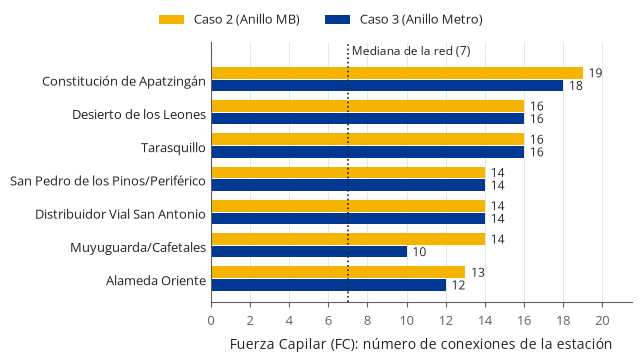

In [5]:
fig = figura(9)
ax = fig.add_subplot()
y = np.arange(len(g1))[::-1]
h = 0.38
b2 = ax.barh(y + h / 2, g1.mb, height=h - 0.03, color=COL["mb"], label=ETQ["mb"])
b3 = ax.barh(y - h / 2, g1.metro, height=h - 0.03, color=COL["metro"], label=ETQ["metro"])
etiquetar_barras(ax, b2); etiquetar_barras(ax, b3)
ax.axvline(mediana_fc, color=TINTA, ls=":", lw=1.2)
ax.text(mediana_fc + 0.2, y.max() + 0.62, f"Mediana de la red ({mediana_fc:.0f})", fontsize=8.5, color=TINTA, va="bottom")
ax.set_yticks(y, g1.nombre)
ax.set_xlabel("Fuerza Capilar (FC): número de conexiones de la estación")
ax.set_xlim(0, max(g1.mb.max(), g1.metro.max()) + 2.5)
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
ax.set_ylim(-0.7, y.max() + 1.1)
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
fig.legend(loc="outside upper center", ncols=2)
guardar(fig, "Grafica_FC_Estaciones_Anillo")
plt.show()

## G2 · §6.3.2 FC — nodos existentes que ganan conexiones, por sistema

**Archivo:** `Grafica_FC_Ganancia_Sistema.{pdf,png}`

| | |
|---|---|
| Fuente | `fc_distribucion_*.csv` de los tres casos (`fc_total`, `sistemas`) |
| Filtros | Nodos con `id` presente en Caso 1. Un nodo «gana» si su `fc_total` en el caso propuesto es mayor que en Caso 1. Sistema = valor de `sistemas` (todos los nodos que ganan tienen un solo sistema) |
| Cifras verificadas | Caso 2: 142 nodos · Caso 3: 138 · CC 73/73 · RTP 60/60 · Metrobús 5/2 · Metro 2/1 · Trolebús 1/1 · **Cablebús 1/1** · ningún nodo pierde conexiones |
| Tableau | **Opcional.** Hoja nueva en `dashboard_viz05_garibelt_comparativo.twb`, sección siguiente |

**Observación.** La lista de control no incluye **Cablebús (1/1)**. La suma de los sistemas listados da 141/137 y con Cablebús se llega a los totales verificados de 142/138, así que el control se cumple. La gráfica muestra los seis sistemas.

**Alternativa en Tableau** (`dashboard_viz05_garibelt_comparativo.twb`):
1. Fuentes nuevas en Live: los tres `fc_distribucion_*.csv`, unidos por `id` con un *left join* desde la red actual. Una tabla de nodos por caso en formato largo también sirve.
2. Campo calculado: `Gana MB = IF [Fc Total (mb)] > [Fc Total (base)] THEN 1 ELSE 0 END` y su análogo para Metro.
3. Hoja «Ganancia de FC por sistema»: Filas = `Sistemas` con alias de nombre completo; Columnas = `SUM(Gana MB)` y `SUM(Gana Metro)` con Measure Names en color, ocultando el encabezado de Measure Names. Colores: Caso 2 `#F4B400` y Caso 3 `#003893`. Etiquetas activas.
4. Filtro: `Gana MB + Gana Metro > 0`.

Python resulta más sencillo, porque la unión de tres CSV en Tableau añade una fuente solo para seis barras.

*Pie sugerido:* «Nodos existentes que ganan conexiones de Fuerza Capilar (FC) por sistema, Caso 2 (Anillo MB) y Caso 3 (Anillo Metro). Ningún nodo pierde conexiones. Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

→ analysis/notebooks/output/cap6/Grafica_FC_Ganancia_Sistema.pdf y .png


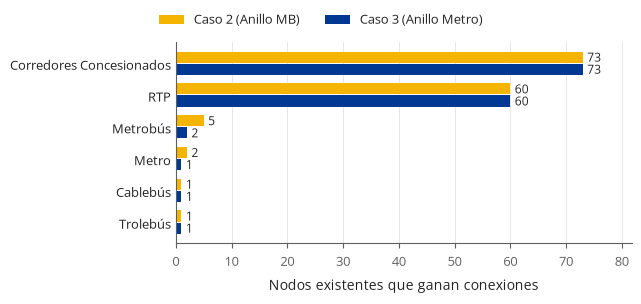

In [6]:
fig = figura(7.5)
ax = fig.add_subplot()
y = np.arange(len(g2))
h = 0.38
b2 = ax.barh(y + h / 2, g2.mb, height=h - 0.03, color=COL["mb"], label=ETQ["mb"])
b3 = ax.barh(y - h / 2, g2.metro, height=h - 0.03, color=COL["metro"], label=ETQ["metro"])
etiquetar_barras(ax, b2, dx=0.8); etiquetar_barras(ax, b3, dx=0.8)
ax.set_yticks(y, [NOMBRE_SISTEMA.get(s, s) for s in g2.index])
ax.set_xlabel("Nodos existentes que ganan conexiones")
ax.set_xlim(0, g2.values.max() * 1.12)
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
fig.legend(loc="outside upper center", ncols=2)
guardar(fig, "Grafica_FC_Ganancia_Sistema")
plt.show()

## G3 · §6.3.3 T — tiempo de viaje promedio de los tres casos

**Archivo:** `Grafica_T_Casos.{pdf,png}`

| | |
|---|---|
| Fuente | `tableau/connectors/VFTModel/exports/{,scenario_mb/,scenario_metro/}wdc_t_escalar.csv` (`T_minutos`, `referencia_cdmx`) |
| Filtros | Ninguno. T es el promedio de caminos más cortos ponderados por impedancia sobre la componente gigante: 10,610 nodos en Caso 1 y 10,707 en Casos 2 y 3 |
| Cifras verificadas | 113.91 / 108.99 / 101.92 min · tiempo de referencia del modelo 85 min · cota de normalización 180 min, con T normalizado = (180 − T) / 95 |
| Tableau | **Ya existe una versión.** `dashboard_viz04_red_vftmodel.twb` tiene T con la referencia, pero solo por caso. Para el Cap. 6 conviene esta gráfica de Python, que reúne los tres casos con la misma escala |

En el CSV la columna se llama `referencia_cdmx`. En la gráfica se rotula «tiempo de referencia del modelo (85 min)».

*Pie sugerido:* «Tiempo de viaje promedio (T) en los tres casos. Línea discontinua: tiempo de referencia del modelo (85 min); línea punteada: cota de normalización (180 min). Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

→ analysis/notebooks/output/cap6/Grafica_T_Casos.pdf y .png


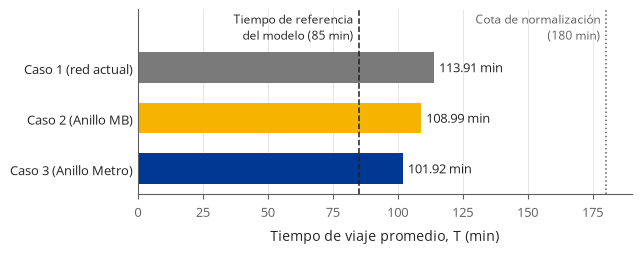

In [7]:
fig = figura(6.2)
ax = fig.add_subplot()
orden = list(CASOS)[::-1]                       # Caso 1 arriba
barras = ax.barh(range(3), [g3[k] for k in orden], color=[COL[k] for k in orden], height=0.6)
for b, k in zip(barras, orden):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, f"{g3[k]:.2f} min", va="center", fontsize=9)
ax.set_yticks(range(3), [ETQ[k] for k in orden])
ax.axvline(T_REFERENCIA, color=TINTA, ls="--", lw=1.1)
ax.axvline(T_COTA, color=TINTA_SEC, ls=":", lw=1.1)
ax.text(T_REFERENCIA - 2, 2.48, f"Tiempo de referencia\ndel modelo ({T_REFERENCIA:.0f} min)", ha="right", va="bottom", fontsize=8.5)
ax.text(T_COTA - 2, 2.48, f"Cota de normalización\n({T_COTA:.0f} min)", ha="right", va="bottom", fontsize=8.5, color=TINTA_SEC)
ax.set_xlim(0, 190); ax.set_ylim(-0.5, 3.15)
ax.set_xlabel("Tiempo de viaje promedio, T (min)")
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
guardar(fig, "Grafica_T_Casos")
plt.show()

## G4 · §6.3.3 T — distribución de los tiempos t_ij por caso

**Archivo:** `Grafica_T_Distribucion.{pdf,png}`

| | |
|---|---|
| Fuente | `../VFTModel/notebooks/ASSETS/t_distribucion/t_histograma_{baseline,mb,metro}.csv` (`intervalo_inf_min`, `intervalo_sup_min`, `pct_pares`), generados por `VFTModel/notebooks/08_Distribucion_T.ipynb` el 2026-10-23 con la corrida 2026-10-04; resumen en `t_resumen_*.csv` |
| Método | Todos los pares origen-destino de la componente gigante: 112,561,490 en Caso 1 y 114,629,142 en Casos 2 y 3. Un Dijkstra por origen, sin guardar la matriz. Intervalos de 5 min [a, a+5). `pct_pares` ya está en porcentaje |
| Filtros | Ninguno. El eje x va de 0 a 600 min; el máximo es 595.3 / 578.5 / 552.3 min |
| Cifras verificadas (consistencia interna) | Cada histograma suma 100% y su conteo coincide con N(N−1). Media de t_ij = T de G3: 113.91 / 108.99 / 101.92. 0 pares inalcanzables. Mediana 99.6 / 96.2 / 89.7 min. Pares con t ≤ 85 min: 38.5% / 40.4% / 45.6%. Pares con t > 180 min: 14.3% / 11.9% / 9.4% |
| Tableau | **No conviene.** Son tres series escalonadas superpuestas con líneas de referencia; el PDF vectorial es más limpio |

Cada escalón de las curvas es el porcentaje de pares en un intervalo de 5 min. El Caso 3 desplaza pares de la cola larga (más de 180 min) hacia tiempos menores.

*Pie sugerido:* «Distribución de los tiempos mínimos de viaje t_ij entre todos los pares origen-destino de la componente gigante, por caso (intervalos de 5 min). Línea discontinua: tiempo de referencia del modelo (85 min); línea punteada: cota de normalización (180 min). Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

→ analysis/notebooks/output/cap6/Grafica_T_Distribucion.pdf y .png


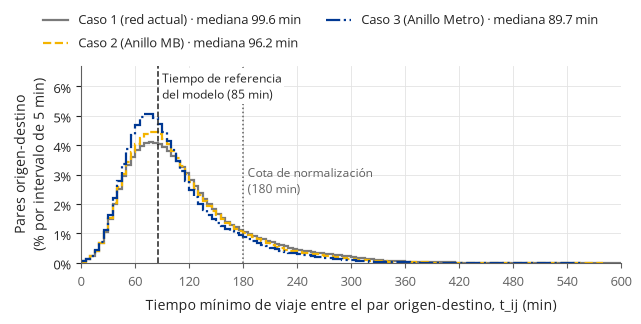

In [8]:
fig = figura(8)
ax = fig.add_subplot()
for k in CASOS:
    h = hist[k]
    bordes = np.r_[h.intervalo_inf_min.to_numpy(), h.intervalo_sup_min.iloc[-1]]
    ax.stairs(h.pct_pares.to_numpy(), bordes, color=COL[k], ls=LS[k], lw=1.6,
              label=f"{ETQ[k]} · mediana {float(t_resumen[k].mediana_min):.1f} min")
ymax = max(hist[k].pct_pares.max() for k in CASOS) * 1.32
ax.axvline(T_REFERENCIA, color=TINTA, ls="--", lw=1.1)
ax.axvline(T_COTA, color=TINTA_SEC, ls=":", lw=1.1)
ax.text(T_REFERENCIA + 5, ymax * 0.98, "Tiempo de referencia\ndel modelo (85 min)", va="top", fontsize=8.5,
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
ax.text(T_COTA + 5, ymax * 0.50, "Cota de normalización\n(180 min)", va="top", fontsize=8.5, color=TINTA_SEC)
ax.set_xlim(0, X_MAX_G4); ax.set_ylim(0, ymax)
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(60))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100, decimals=0))
ax.set_xlabel("Tiempo mínimo de viaje entre el par origen-destino, t_ij (min)")
ax.set_ylabel("Pares origen-destino\n(% por intervalo de 5 min)")
ax.grid(True); ax.set_axisbelow(True)
fig.legend(loc="outside upper center", ncols=2)
guardar(fig, "Grafica_T_Distribucion")
plt.show()

## G5 · §6.3.4 B(v) — curva de Lorenz de la Centralidad de Intermediación

**Archivo:** `Grafica_BV_Lorenz.{pdf,png}`

| | |
|---|---|
| Fuente | `comparativo/bv_comparativo.csv` (`bv_baseline`, `bv_mb`, `bv_metro`) |
| Filtros | Nodos con valor de B(v) en cada caso, es decir, la componente gigante: 10,610 / 10,707 / 10,707. Los nodos sin valor no se cuentan como cero. Con ellos como cero el Gini sería 0.8113 / 0.8101 / 0.8217, que no es lo que reporta el perfil |
| Cifras verificadas | Gini 0.8007 / 0.8012 / 0.8134 |
| Tableau | **No conviene.** La curva de Lorenz necesita cálculos de tabla (`RUNNING_SUM`, `INDEX()/SIZE()`) sobre 10,700 marcas por caso, y el resultado no es vectorial |

Las tres curvas casi se superponen en la escala completa. El panel derecho amplía el recuadro punteado, que corresponde al 10% de nodos con mayor B(v). Ahí se ve que el Caso 3 queda por debajo de los otros dos, es decir, más concentrado.

*Pie sugerido:* «Curva de Lorenz de la Centralidad de Intermediación B(v) en los tres casos. La diagonal representa una distribución perfectamente igualitaria. Gini: 0.8007 (Caso 1), 0.8012 (Caso 2) y 0.8134 (Caso 3). Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

→ analysis/notebooks/output/cap6/Grafica_BV_Lorenz.pdf y .png


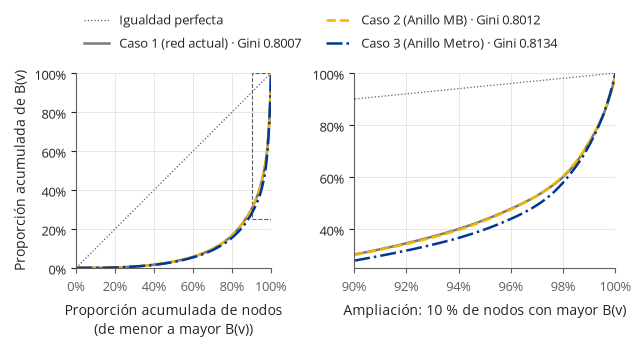

In [9]:
fig = figura(8.6)
ax, az = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1]})
curvas = {k: lorenz(bv[c].dropna()) for k, c in COL_BV.items()}
fmt_pct = mpl.ticker.PercentFormatter(1.0, decimals=0)
x0 = 0.90                                    # ampliación: 10 % de nodos con mayor B(v)
y0 = np.floor((min(np.interp(x0, *curvas[k]) for k in curvas) - 0.02) * 20) / 20
for eje in (ax, az):
    eje.plot([0, 1], [0, 1], color=TINTA_SEC, lw=0.9, ls=":", label="Igualdad perfecta")
    for k, (x, yv) in curvas.items():
        eje.plot(x, yv, color=COL[k], ls=LS[k], lw=1.8, label=f"{ETQ[k]} · Gini {g5_gini[k]:.4f}")
    eje.grid(True); eje.set_axisbelow(True)
    eje.xaxis.set_major_formatter(fmt_pct); eje.yaxis.set_major_formatter(fmt_pct)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.add_patch(Rectangle((x0, y0), 1 - x0, 1 - y0, fill=False, edgecolor=TINTA_SEC, lw=0.8, ls="--"))
ax.set_xlabel("Proporción acumulada de nodos\n(de menor a mayor B(v))")
ax.set_ylabel("Proporción acumulada de B(v)")
az.set_xlim(x0, 1); az.set_ylim(y0, 1)
az.xaxis.set_major_locator(mpl.ticker.MultipleLocator(0.02))
az.set_xlabel("Ampliación: 10 % de nodos con mayor B(v)")
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=2)
guardar(fig, "Grafica_BV_Lorenz")
plt.show()

## G6 · §6.3.4 B(v) — suma de la Centralidad de Intermediación por alcaldía o municipio

**Archivo:** `Grafica_BV_Alcaldias.{pdf,png}`

| | |
|---|---|
| Fuente | `comparativo/bv_comparativo.csv` (`alcaldia_municipio`, `bv_baseline`, `bv_mb`, `bv_metro`) |
| Filtros | Suma de B(v) por `alcaldia_municipio`. Se muestran las **20** demarcaciones con mayor suma en algún caso; con 20 entra Milpa Alta y quedan todas las alcaldías del sur. Orden: suma en Caso 1, de mayor a menor. Sombreadas: alcaldías del sur, según `ALCALDIAS_SUR` |
| Cifras verificadas | Tacubaya 0.2232 / 0.2163 / 0.1569 (nodo principal, Miguel Hidalgo) |
| Tableau | **Sí conviene como alternativa** (ver abajo); la fuente `bv_comparativo` ya está en el workbook comparativo |

**⚠ Límite de los datos.** `alcaldia_municipio` solo está asignada a **2,362 de 11,209 nodos**: los que aparecen en el orden 1–2,000 de B(v) de algún caso (`b_ranking_*.csv`). Esos nodos concentran **83.8% / 84.3% / 85.2%** de la B(v) total de cada caso. El resto, con B(v) ≤ 0.0032 por nodo, queda sin demarcación. La suma por alcaldía es, por tanto, la suma de los nodos con mayor intermediación, y así hay que decirlo en el pie. Para cubrir el 100% habría que asignar la demarcación por coordenadas (`lon`, `lat`) con la capa de límites políticos. Eso queda fuera de este notebook, que solo lee lo exportado.

**Alcaldías del sur.** Es una decisión del autor y no viene de los datos. Se usan Álvaro Obregón, Coyoacán, La Magdalena Contreras, Tlalpan, Xochimilco, Tláhuac y Milpa Alta. Iztapalapa queda fuera porque se considera oriente. Se cambia en `ALCALDIAS_SUR`, en la celda de carga.

**Alternativa en Tableau** (`dashboard_viz05_garibelt_comparativo.twb`, fuente `bv_comparativo` ya pivotada):
- Hoja «B(v) por alcaldía»: Filas = `Alcaldia Municipio`; Columnas = `SUM(B(v))`; Color = `Escenario` con alias Caso 1/2/3 y colores `#7A7A7A` / `#F4B400` / `#003893`.
- Filtro por `Alcaldia Municipio`: Top 20 por `MAX` de `SUM(B(v))`, que requiere un campo `{FIXED [Alcaldia Municipio], [Escenario] : SUM([B(v)])}`. Excluir Null.
- Conjunto «Sur» con las siete alcaldías, arrastrado a Filas antes de la alcaldía, o como borde o fondo.
- Ocultar el encabezado de Escenario.

*Pie sugerido:* «Suma de la Centralidad de Intermediación B(v) por alcaldía o municipio en los tres casos, para los nodos que están entre los 2,000 de mayor B(v) en algún caso (84%–85% de la B(v) total). Sombreadas: alcaldías del sur. Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

findfont: Failed to find font weight bold, now using 800.


→ analysis/notebooks/output/cap6/Grafica_BV_Alcaldias.pdf y .png


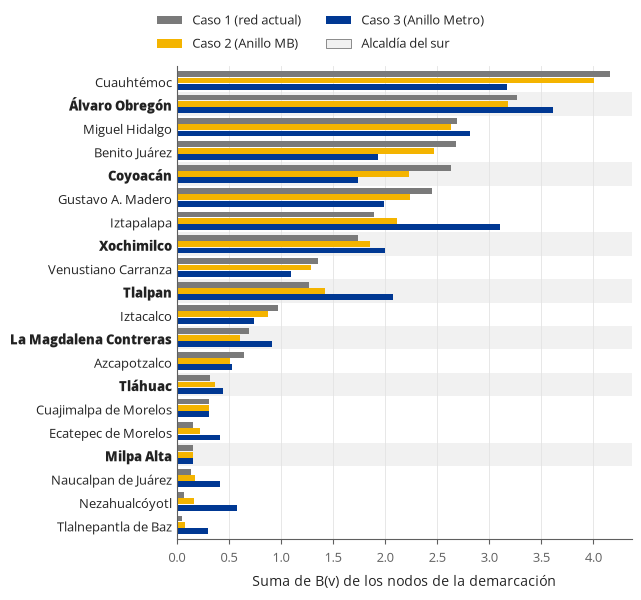

In [10]:
d = g6.sort_values("base", ascending=True)       # mayor arriba
fig = figura(15)
ax = fig.add_subplot()
y = np.arange(len(d))
h = 0.27
for i, k in enumerate(CASOS):                     # Caso 1 arriba dentro de cada grupo
    ax.barh(y + (1 - i) * h, d[k], height=h - 0.02, color=COL[k], label=ETQ[k])
for yi, nombre in zip(y, d.index):
    if nombre in ALCALDIAS_SUR:
        ax.axhspan(yi - 0.5, yi + 0.5, color=FONDO_SUR, zorder=0, lw=0)
ax.set_yticks(y, d.index)
for t in ax.get_yticklabels():
    if t.get_text() in ALCALDIAS_SUR:
        t.set_fontweight("bold")
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlabel("Suma de B(v) de los nodos de la demarcación")
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor=FONDO_SUR, edgecolor=TINTA_SEC, lw=0.5)); labels.append("Alcaldía del sur")
fig.legend(handles, labels, loc="outside upper center", ncols=2)
guardar(fig, "Grafica_BV_Alcaldias")
plt.show()

## G7 · §6.4 Espectro MJG — transición de banda dominante por nodo

**Archivo:** `Grafica_Espectro_Transicion_Banda.{pdf,png}`

| | |
|---|---|
| Fuente | `comparativo/transicion_bandas.csv`, `dimension == "banda_dominante"` |
| Definición | Banda dominante de un nodo = intervalo del **mínimo** entre su FC normalizada y su B(v) normalizada (VFTModel, `network_profile.py`, `_dominant_band`). Umbrales 0.25, 0.50 y 0.75 (`normalization.py`, `classify_band`). Se rotulan como intervalos: 0–0.25, 0.25–0.50, 0.50–0.75. Ningún nodo llega a 0.75–1.0 en ningún caso, así que esa fila y esa columna se omiten |
| Filtros | Matriz de Caso 1 a Caso 2 y de Caso 1 a Caso 3. La fila «Estación nueva» son los nodos que no existen en Caso 1 (Caso 2: 94; Caso 3: 94) y no cuentan como cambio |
| Cifras verificadas | Cambian de intervalo **10** nodos existentes en Caso 2 (4 suben a 0.25–0.50 y 6 bajan a 0–0.25) y **21** en Caso 3 (11 suben y 10 bajan) |
| Tableau | **Alternativa viable**: tabla resaltada (*highlight table*) |

**Por qué matriz y no diagrama aluvial.** Casi todos los nodos se quedan en 0–0.25: 11,041 en Caso 2 y 11,034 en Caso 3. En un aluvial el flujo que no cambia tapa los 10 y 21 cambios, que son justamente lo que interesa. La matriz muestra todos los conteos y destaca las celdas que cambian con el color del caso.

**Alternativa en Tableau** (`dashboard_viz05_garibelt_comparativo.twb`, fuente nueva `transicion_bandas.csv` en Live):
- Filtro `Dimension = banda_dominante`.
- Filas = `Banda Origen`; Columnas = `Escenario Label` y `Banda Destino`; Marca Cuadrado; Texto = `SUM(N Nodos)`.
- Color = calculado `IF [Cambia] THEN [Escenario Label] ELSE "Sin cambio" END`, con Anillo MB `#F4B400`, Anillo Metro `#003893` y Sin cambio gris claro.
- Alias de bandas: critico → 0–0.25, debil → 0.25–0.50, aceptable → 0.50–0.75, nuevo → Estación nueva.

*Pie sugerido:* «Transición del intervalo del valor normalizado dominante (mínimo entre FC y B(v)) por nodo, del Caso 1 (red actual) al Caso 2 (Anillo MB) y al Caso 3 (Anillo Metro). Las celdas de color son nodos que cambian de intervalo. Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

findfont: Failed to find font weight bold, now using 800.


→ analysis/notebooks/output/cap6/Grafica_Espectro_Transicion_Banda.pdf y .png


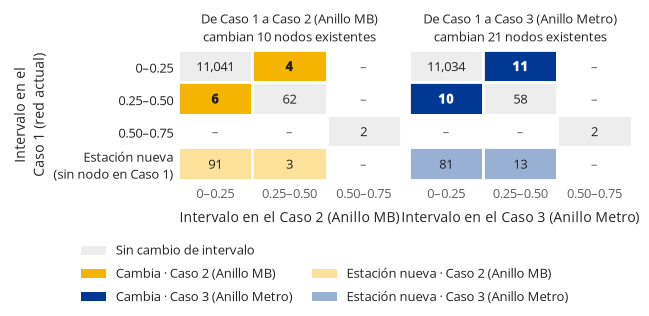

In [11]:
ORIGEN = ["critico", "debil", "aceptable", "nuevo"]
DESTINO = ["critico", "debil", "aceptable"]
assert set(g7.banda_destino) <= set(DESTINO) and set(g7.banda_origen) <= set(ORIGEN), "Hay bandas no previstas"
etq_origen = [INTERVALO.get(b, "Estación nueva\n(sin nodo en Caso 1)") for b in ORIGEN]

fig = figura(7.8)
axs = fig.subplots(1, 2, sharey=True)
for ax, k in zip(axs, ("mb", "metro")):
    m = (g7[g7.escenario_destino == k].pivot_table(index="banda_origen", columns="banda_destino",
                                                   values="n_nodos", aggfunc="sum")
         .reindex(index=ORIGEN, columns=DESTINO).fillna(0).astype(int))
    texto_sobre = "white" if k == "metro" else TINTA
    for i, bo in enumerate(ORIGEN):
        for j, bd in enumerate(DESTINO):
            n = m.loc[bo, bd]
            if bo == "nuevo":
                fc_, tc, hatch, alpha = (tono(COL[k], 0.6) if n else "white"), (TINTA if n else TINTA_SEC), None, 1
            elif bo == bd:
                fc_, tc, hatch, alpha = "#EDEDED", TINTA, None, 1
            else:
                fc_, tc, hatch, alpha = (COL[k] if n else "white"), (texto_sobre if n else TINTA_SEC), None, 1
            yy = len(ORIGEN) - 1 - i
            ax.add_patch(Rectangle((j, yy), 1, 1, facecolor=fc_, alpha=alpha, edgecolor="white", lw=2, hatch=hatch))
            ax.text(j + 0.5, yy + 0.5, f"{n:,}" if n else "–", ha="center", va="center", fontsize=9.5,
                    color=TINTA if (bo == "nuevo" and n) else tc,
                    fontweight="bold" if (bo != bd and bo != "nuevo" and n) else "normal")
    ax.set_xlim(0, len(DESTINO)); ax.set_ylim(0, len(ORIGEN))
    ax.set_xticks(np.arange(len(DESTINO)) + 0.5, [INTERVALO[b] for b in DESTINO])
    ax.set_yticks(np.arange(len(ORIGEN)) + 0.5, etq_origen[::-1])
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xlabel(f"Intervalo en el {ETQ[k]}")
    ax.set_title(f"De Caso 1 a {ETQ[k]}\ncambian {g7_cambian[k]} nodos existentes",
                 fontsize=9.5, color=TINTA)
axs[0].set_ylabel("Intervalo en el\nCaso 1 (red actual)")
leyenda = [Patch(facecolor="#EDEDED", label="Sin cambio de intervalo"),
           Patch(facecolor=COL["mb"], label=f"Cambia · {ETQ['mb']}"),
           Patch(facecolor=COL["metro"], label=f"Cambia · {ETQ['metro']}"),
           Patch(facecolor="white", edgecolor="white", label=""),
           Patch(facecolor=tono(COL["mb"], 0.6), label=f"Estación nueva · {ETQ['mb']}"),
           Patch(facecolor=tono(COL["metro"], 0.6), label=f"Estación nueva · {ETQ['metro']}")]
fig.legend(handles=leyenda, loc="outside lower center", ncols=2, columnspacing=1.5)
guardar(fig, "Grafica_Espectro_Transicion_Banda")
plt.show()

## G8 · §6.3.3 T — cambio del tiempo medio desde el nodo, por demarcación

**Archivo:** `Grafica_T_Demarcacion.{pdf,png}`

| | |
|---|---|
| Fuente | `../VFTModel/notebooks/ASSETS/t_distribucion/t_comparativo_origen.csv` (`alcaldia_municipio`, `delta_mb_min`, `delta_metro_min`); control con `t_comparativo_comun.csv` |
| Definición | Para cada nodo de origen, el tiempo medio a todos los destinos del **conjunto común**: los 10,610 nodos de la componente gigante del Caso 1. Δ = caso − Caso 1, en minutos; negativo es mejora. Los caminos pueden pasar por cualquier nodo del caso, incluidas las estaciones del anillo |
| Agregación | Media de Δ por `alcaldia_municipio`, con las 29 demarcaciones. Orden: de mayor a menor mejora en el Caso 3. Junto al nombre va el número de nodos (n) |
| Marcadas | Demarcaciones con n ≤ 17 nodos (†, barras en tono claro): Chimalhuacán, Huixquilucan, Valle de Chalco Solidaridad, La Paz, Cuautitlán Izcalli, Cuautitlán, Tultitlán, Coacalco de Berriozábal y Tecámac. Su media descansa en muy pocos nodos |
| Cifras verificadas (consistencia interna) | 10,610 nodos, todos con demarcación. La media de Δ por origen es −4.6998 min (Caso 2) y −11.5044 min (Caso 3), igual al ΔT del conjunto común. **Todos los nodos mejoran en ambos casos** |
| Tableau | **Opcional**: barras pareadas con `t_comparativo_origen.csv` (ver abajo). El mapa de puntos va en QGIS, no en Tableau |

**Observaciones de los datos:**
- **Mayor mejora.** Está en Nezahualcóyotl: −43.9 min en el Caso 2 y −59.7 en el Caso 3, con n = 79. Le siguen Chimalhuacán (n = 11) y Ecatepec de Morelos (n = 110).
- **Valores repetidos.** Cuautitlán, Cuautitlán Izcalli, Tultitlán y Coacalco de Berriozábal tienen exactamente el mismo Δ (−2.88 / −5.41 min). Las cuatro tienen n ≤ 17. El notebook no interpreta la causa.
- **Otra fuente posible.** También sirve `t_alcaldia_*.csv`, pero mide el tiempo medio hacia todos los destinos de cada caso, que son conjuntos distintos. Para comparar casos conviene `t_comparativo_origen.csv`.

**Mapa de puntos (opcional).** `t_comparativo_origen.csv` trae `lon` y `lat` por nodo. Según el reparto del proyecto, los mapas van en QGIS: se carga como capa de texto delimitado (EPSG:4326) y se simboliza por `delta_metro_min` con una rampa de un solo tono. No se genera aquí.

**Alternativa en Tableau.** Fuente `t_comparativo_origen.csv` en Live:
- Filas = `Alcaldia Municipio` ordenada por `AVG(Delta Metro Min)`.
- Columnas = `AVG(Delta Mb Min)` y `AVG(Delta Metro Min)`, con Measure Names en color y el encabezado oculto.
- Etiqueta de n con `COUNT([Id])`.
- Conjunto «n ≤ 17» en el detalle o como borde.

*Pie sugerido:* «Cambio medio del tiempo de viaje desde cada nodo hacia los 10,610 nodos de la red actual, por alcaldía o municipio, en el Caso 2 (Anillo MB) y el Caso 3 (Anillo Metro) frente al Caso 1 (red actual). Valores negativos indican menor tiempo. n: número de nodos; †: demarcaciones con 17 nodos o menos. Fuente: elaboración propia con datos de Apímetro y VFTModel (corrida 2026-10-04), 2026.»

→ analysis/notebooks/output/cap6/Grafica_T_Demarcacion.pdf y .png


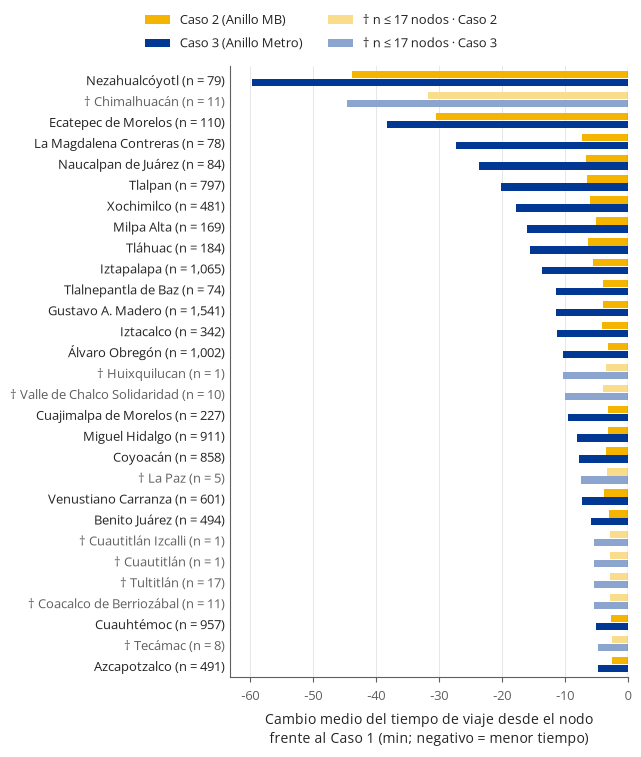

In [12]:
d = g8.iloc[::-1]                                # mayor mejora del Caso 3 arriba
pocos = (d.n <= N_POCOS).to_numpy()
fig = figura(19)
ax = fig.add_subplot()
y = np.arange(len(d))
h = 0.38
for desp, k in ((h / 2, "mb"), (-h / 2, "metro")):
    colores = [tono(COL[k], 0.55) if p else COL[k] for p in pocos]
    ax.barh(y + desp, d[k], height=h - 0.03, color=colores)
etiquetas = [f"{'† ' if p else ''}{nom} (n = {n:,})" for nom, n, p in zip(d.index, d.n, pocos)]
ax.set_yticks(y, etiquetas)
for t, p in zip(ax.get_yticklabels(), pocos):
    if p:
        t.set_color(TINTA_SEC)
ax.axvline(0, color=TINTA, lw=0.8)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlim(min(d.metro.min(), d.mb.min()) * 1.06, 0)
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(10))
ax.set_xlabel("Cambio medio del tiempo de viaje desde el nodo\nfrente al Caso 1 (min; negativo = menor tiempo)")
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
handles = [Patch(facecolor=COL["mb"]), Patch(facecolor=COL["metro"]),
           Patch(facecolor=tono(COL["mb"], 0.55)), Patch(facecolor=tono(COL["metro"], 0.55))]
labels = [ETQ["mb"], ETQ["metro"], f"† n ≤ {N_POCOS} nodos · Caso 2", f"† n ≤ {N_POCOS} nodos · Caso 3"]
fig.legend(handles, labels, loc="outside upper center", ncols=2)
guardar(fig, "Grafica_T_Demarcacion")
plt.show()

## Resumen de salidas

In [13]:
pd.DataFrame([(p.name, f"{p.stat().st_size/1024:.0f} KB") for p in sorted(OUT.glob("*"))],
             columns=["archivo", "tamaño"])

,archivo,tamaño
0,Grafica_BV_Alcaldias.pdf,44 KB
1,Grafica_BV_Alcaldias.png,142 KB
2,Grafica_BV_Lorenz.pdf,40 KB
3,Grafica_BV_Lorenz.png,175 KB
4,Grafica_Espectro_Transicion_Banda.pdf,41 KB
5,Grafica_Espectro_Transicion_Banda.png,136 KB
6,Grafica_FC_Estaciones_Anillo.pdf,40 KB
7,Grafica_FC_Estaciones_Anillo.png,97 KB
8,Grafica_FC_Ganancia_Sistema.pdf,33 KB
9,Grafica_FC_Ganancia_Sistema.png,63 KB
